# 49 · 선호 쌍에서 DPO 목적 만들기

같은 과일·색 지시에 두 답변을 보여 주고 어느 쪽이 더 나은지 표시합니다. 좋은 답변만 외우는 SFT에서 한 걸음 더 나아가 **두 답변의 상대 변화**를 학습합니다. 그 순위가 좋아지는 것과 새 답변을 잘 생성하는 것은 따로 확인합니다.

- 준비물: [12 확률과 정보](../02_연결/12_gaussian_information.ipynb), [45 decoder 전체 미분](45_decoder_gpt.ipynb), [48 답변 손실](48_sft_lora.ipynb)입니다.
- 순서: ① 선호 확률 → ② sequence 로그확률 → ③ 기준 모델과 DPO → ④ 실제 SFT/DPO → ⑤ 자유 생성과 목적의 한계입니다.
- 범위: 작은 합성 선호 규칙을 사용합니다. 사람의 복잡한 가치나 실제 서비스 품질을 측정하는 실험은 아닙니다. 외부 pretrained/API 없이 decoder를 처음부터 학습합니다.

> **용어** · **chosen/rejected**는 한 prompt에서 더 선호하는 답변과 덜 선호하는 답변입니다. **정책(policy)** π는 조건에 따른 다음 token 확률 모델입니다. **reference**는 비교 기준으로 고정한 정책입니다. **DPO**는 기준 정책 대비 두 답변의 로그확률 변화 차이로 선호를 학습하는 목적입니다. **logits**는 softmax 전 어휘 점수입니다.

### 읽는 법

| 표시 | 확인할 것 |
|---|---|
| 🔑 핵심 | 선호·확률·미분 연결 |
| 🔍 확인 | 수치 검산·생성·한계 |
| 📎 참고 | 용어·출처·구현 범위 |
| ✏️ 연습 | 핵심 한두 줄 구성 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 답변의 확률은 EOS까지 조건부 확률을 곱하며 로그공간에서는 더합니다.
2. DPO의 reference는 고정하고 chosen/rejected의 전체 미분을 공유 파라미터에 더합니다.
3. 상대 선호 개선·절대 답변 확률·자유 생성을 각각 평가합니다.

[그림 보조 코드](../../src/utils/dpo_plots.py) · [학습 경로](../../docs/CURRICULUM.md)

In [1]:
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.dpo_plots import (
    plot_preference_probability,plot_sequence_sum,plot_reference_margin,
    plot_objective_signals,plot_dpo_learning,plot_absolute_probabilities,
)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 답변 두 개의 점수 차이를 확률로 읽습니다

**이 절에서 가져갈 것:** 선호 확률은 두 점수의 차이에 달려 있고, 공통 상수를 더해도 같습니다.

빨강을 다음 색인 초록으로 바꾸라는 지시에 `초록`과 `빨강`이 나왔습니다. 첫 답변의 점수 r⁺가 더 크면 그 답변을 선호할 확률을 크게 둡니다.

$$P(y^+\succ y^-\mid x)=\sigma(r^+-r^-),\qquad\sigma(u)=\frac1{1+e^{-u}}.$$

점수는 표본마다 숫자 하나이고 배치에서는 `(N,)`입니다. 차이가0이면 확률.5, 차이가2이면 약.881입니다. 관측된 chosen을 맞히는 음의 로그우도는 $-\log\sigma(u)=\log(1+e^{-u})$입니다. 작은 확률의 log를 직접 취하지 않고 `np.logaddexp(0,-u)`로 계산합니다.

> **용어** · **Bradley–Terry 모형**은 두 대상의 점수 차이를 sigmoid에 넣어 비교 확률로 만드는 모형입니다. **선호 라벨**은 절대 점수 대신 어느 답변이 더 나은지 표시합니다. 같은 prompt에 공통 상수를 더한 점수는 이 비교로 구별되지 않습니다.

In [2]:
score_differences=np.array([-2.,0.,2.])
preference_probabilities=np.array([1/(1+np.exp(2)),.5,1/(1+np.exp(-2))])

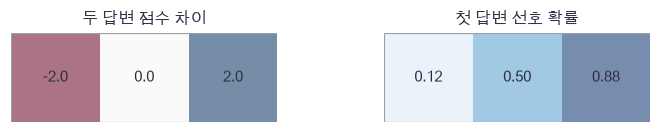

In [3]:
plot_preference_probability(score_differences,preference_probabilities)

🔍 **확인** · 더 큰 차이가 더 큰 선호 확률을 만듭니다. 차이가0인 것은 두 답변이 실제로 같은 품질이라는 확정이 아니라, 이 모형이 동률 점수를 줬다는 뜻입니다.

In [4]:
def sigmoid_stable(values):
    """큰 음수·양수에서도 유한한 sigmoid 값을 계산합니다."""
    return np.exp(-np.logaddexp(0.,-values))

In [5]:
probability_loop=[]
for difference in score_differences:
    probability_loop.append(1/(1+np.exp(-difference)))
np.testing.assert_allclose(probability_loop,sigmoid_stable(score_differences))  # 검산: 손계산·반복문·벡터화 일치
np.testing.assert_allclose(sigmoid_stable(np.array([-1000.,1000.])),[0.,1.])  # 검산: 극단 점수도 유한
assert np.isfinite(np.logaddexp(0.,1000.)), '극단 음의 margin 손실도 유한해야 합니다'
print('선호 확률·수치 안정성 검산 통과')

선호 확률·수치 안정성 검산 통과


### ✏️ 연습 1 · 공통 점수 이동

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

두 점수의 차이를 채우세요.

In [6]:
def exercise_difference(chosen, rejected):
    """공통 점수 이동의 계산을 완성합니다."""
    ### 구현할 내용: 두 점수의 차이를 채우세요.
    raise NotImplementedError
    return difference

In [7]:
def check_difference(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([4.,104.]),np.array([2.,102.])),[2.,2.])  # 검산: 공통 상수 이동 불변
    print("연습 1 통과")

run_check(check_difference, exercise_difference, hint="공통 점수 이동의 수식과 축을 확인하세요.")

☐ exercise_difference: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 공통 점수 이동의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
difference = chosen - rejected
```

</details>

## 🔑 2. 답변의 로그확률은 token 축으로 더합니다

**이 절에서 가져갈 것:** prompt와 PAD를 제외하고 답변+EOS를 합해야 sequence 확률이 됩니다.

같은 지시에 짧은 답변 `[초록,EOS]`와 긴 답변 `[초록,과일,EOS]`를 붙입니다. 다음 token의 확률은 앞 token에 조건을 걸고 곱합니다.

$$\ell_\theta(x,y)=\log\pi_\theta(y\mid x)=\sum_t w_t\log p_\theta(y_t\mid x,y_{<t}).$$

logits는 `(N,T,V)`, target과 답변 mask w는 `(N,T)`, 합 ℓ은 `(N,)`입니다. $w=1$은 답변 또는EOS, prompt와PAD는0입니다. **길이로 나누면 다른 목적**이 됩니다. 빈 답변도 EOS 확률 하나를 가집니다.

> **용어** · **BOS/EOS/PAD/SEP**는 시작·종료·빈칸·prompt/답변 경계 token입니다. 여기서는 ID0=PAD,1=BOS,2=EOS,3=SEP입니다. **teacher forcing**은 답변 확률을 계산할 때 정답의 앞부분을 입력으로 주는 방식입니다.
>
> **코드** · `np.take_along_axis(log_probs,targets[...,None],axis=-1)`는 각 위치의 정답 어휘 점수만 고릅니다. `[...,None]`은 마지막 축을 하나 추가합니다. `sum(axis=1)`은 시간 token 축을 더합니다. `zip`은 대응 목록을 함께 읽습니다.

In [8]:
selected_log_hand=np.log(np.array([[.2,.4,.8],[.2,.4,.8]]))
response_mask_hand=np.array([[0.,1.,1.],[0.,0.,1.]])
sequence_sum_hand=(selected_log_hand*response_mask_hand).sum(axis=1)

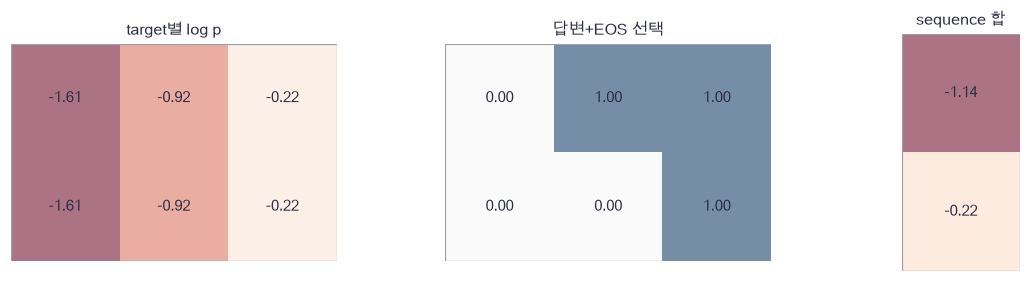

In [9]:
plot_sequence_sum(selected_log_hand,response_mask_hand,sequence_sum_hand)

🔍 **확인** · 첫 문서의 답변 확률은 .4×.8=.32, 둘째는.8입니다. 선택한 token 수로 나누지 않습니다. 이 그림의 수는 설명용이며 서로 다른 실제 문맥의 확률이 같다고 가정하는 학습 모델은 아닙니다.

In [10]:
def response_batch(prompts,responses):
    """BOS·prompt·response·EOS를 이동하고 답변 첫 token부터EOS까지만 loss mask를 켭니다."""
    sequences=[[1]+list(prompt)+list(response)+[2] for prompt,response in zip(prompts,responses)]
    length=max(len(sequence)-1 for sequence in sequences)
    ids=np.zeros((len(sequences),length),dtype=int)
    targets=np.zeros_like(ids)
    valid=np.zeros_like(ids,dtype=bool)
    weights=np.zeros_like(ids,dtype=bool)
    for row,(sequence,prompt) in enumerate(zip(sequences,prompts)):
        count=len(sequence)-1
        ids[row,:count]=sequence[:-1]
        targets[row,:count]=sequence[1:]
        valid[row,:count]=True
        weights[row,len(prompt):count]=True
    return ids,targets,valid,weights

In [11]:
def sequence_log_probs(logits,targets,weights):
    """답변과 EOS의 log probability를 문서별로 더합니다."""
    shifted=logits-logits.max(axis=-1,keepdims=True)
    log_probs=shifted-np.log(np.exp(shifted).sum(axis=-1,keepdims=True))
    selected=np.take_along_axis(log_probs,targets[...,None],axis=-1)[...,0]
    return (selected*weights).sum(axis=1),log_probs

In [12]:
# 쓰는 것: response_mask_hand (앞 절의 정의·실행 셀)
hand_logits=np.log(np.array([[[.2,.8],[.4,.6],[.8,.2]],[[.2,.8],[.4,.6],[.8,.2]]]))
hand_targets=np.zeros((2,3),dtype=int)
hand_sum,_=sequence_log_probs(hand_logits,hand_targets,response_mask_hand)
np.testing.assert_allclose(np.exp(hand_sum),[.32,.8])  # 검산: sequence 합을 지수화 = 확률의 곱
long_short=response_batch([[5,3],[5,6,3]],[[7,8],[8]])
np.testing.assert_array_equal(long_short[3].sum(axis=1),[3,2])  # 검산: 가변 길이 답변에 EOS 하나씩 포함
assert response_batch([[5,3]],[[]])[3].sum()==1, '빈 답변도 EOS 하나입니다'
print('답변 합·가변 길이·EOS 검산 통과')

답변 합·가변 길이·EOS 검산 통과


### ✏️ 연습 2 · 선택 로그확률 합

문서별 답변 로그확률을 채우세요.

In [13]:
def exercise_sumlog(selected, weights):
    """선택 로그확률 합의 계산을 완성합니다."""
    ### 구현할 내용: 문서별 답변 로그확률을 채우세요.
    raise NotImplementedError
    return total

In [14]:
def check_sumlog(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[-9.,-2.,-3.],[-8.,-1.,-7.]]),np.array([[0,1,1],[0,1,0]])),[-5.,-1.])  # 검산: prompt·PAD를 빼고 합
    print("연습 2 통과")

run_check(check_sumlog, exercise_sumlog, hint="선택 로그확률 합의 수식과 축을 확인하세요.")

☐ exercise_sumlog: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 선택 로그확률 합의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = (selected * weights).sum(axis=1)
```

</details>

## 🔑 3. 고정 기준 대비 선호 변화에 미분합니다

**이 절에서 가져갈 것:** 기준 모델은 미분하지 않고, actor의 chosen/rejected 두 경로를 모두 더합니다.

기준 모델이 이미 `빨강`을 강하게 믿고 있었다면 현재 모델의 확률만 비교해서는 얼마나 바뀌었는지 알기 어렵습니다. 두 답변의 **기준 대비 로그확률 변화 차이**를 봅니다.

$$m_n=\beta[(\ell_\theta^+-\ell_\theta^-)-(\ell_{ref}^+-\ell_{ref}^-)],\quad L=-\frac1N\sum_n\log\sigma(m_n).$$

m과 각ℓ은 `(N,)`, β>0은 고정 계수입니다. 같은 actor/reference로 시작하면 m=0,L=log2입니다. $c_n=\beta(\sigma(m_n)-1)/N$이면 $\partial L/\partial\ell_\theta^+=c_n$, $\partial L/\partial\ell_\theta^-=-c_n$입니다.

각 답변의 logits 미분은 $c_nw_{nt}(onehot(y_{nt})-p_{nt})$입니다. 미분은 attention·LN·FFN·embedding·위치·head 전체로 갑니다. 두 답변이 같은 배열을 사용하므로 두 gradient를 더합니다. **분모 N은 선호 쌍 수이며 token 수가 아닙니다.**

이 식은 KL 제약 보상 최적화의 최적 정책을 이용한 [DPO 원문](https://arxiv.org/abs/2305.18290)의 목적입니다. 이번 계산에는 별도 reward model이나 rollout이 없습니다. β가 크면 항상 실제 KL이 작아진다는 보장은 이 유한 학습만으로 하지 않습니다.

In [15]:
policy_hand=np.array([[-2.,-4.],[-4.,-5.]])
reference_hand=np.array([[-3.,-4.],[-3.,-5.]])
margin_hand=.5*((policy_hand[:,0]-policy_hand[:,1])-(reference_hand[:,0]-reference_hand[:,1]))

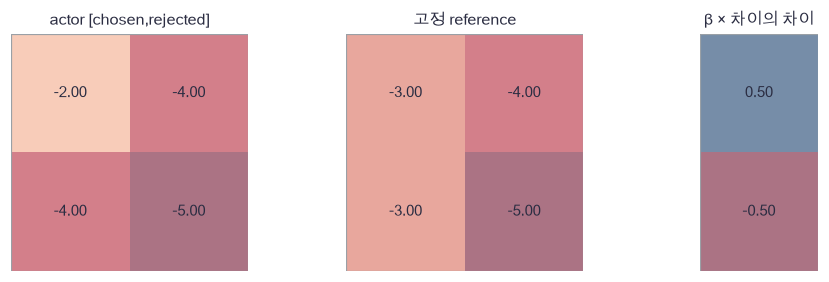

In [16]:
plot_reference_margin(policy_hand,reference_hand,margin_hand)

🔍 **확인** · 둘째 actor는 chosen의 확률이 rejected보다 높지만, 기준 대비 그 차이는 줄었습니다. raw 순위와 DPO margin의 부호는 다를 수 있습니다.

아래 모델은45번과 같은 1개 pre-LN causal attention·tanh FFN·최종 LN decoder입니다. 입력 `(N,T)`→embedding `(N,T,D)`→logits `(N,T,V)`이며, 학습 위치 행렬은 `(Tmax,D)`입니다. 모든 함수 본문을 두어 독립 실행합니다.

> **코드** · `np.add.at`은 반복 token의 embedding gradient를 누적합니다. `reshape(-1,D)`는 N,T축을 합칩니다. `dict.items()`는 이름·배열을 함께 순회합니다. `numerical_gradient`는 배열 원소를 ±h로 바꾼 중심차분 후 원래 값을 복원합니다.

In [17]:
def masked_softmax(scores, allowed):
    """마지막 key 축에서 허용한 점수만 정규화합니다. 전부 막힌 행은0입니다."""
    masked = np.where(allowed, scores, -np.inf)
    maximum = masked.max(axis=-1, keepdims=True)
    maximum = np.where(np.isfinite(maximum), maximum, 0.)
    exponential = np.exp(masked - maximum)
    total = exponential.sum(axis=-1, keepdims=True)
    return np.divide(exponential, total, out=np.zeros_like(exponential), where=total > 0)

In [18]:
def layernorm_forward(x, gamma, beta, epsilon=1e-5):
    """각 token의 마지막 D축을 정규화하고 affine 변환합니다."""
    centered = x - x.mean(axis=-1, keepdims=True)
    inverse = 1 / np.sqrt(np.mean(centered**2, axis=-1, keepdims=True) + epsilon)
    normalized = centered * inverse
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [19]:
def layernorm_backward(upstream, cache):
    """epsilon을 포함한 LayerNorm의 입력·gamma·beta 미분을 반환합니다."""
    normalized, inverse, gamma = cache
    weighted = upstream * gamma
    dx = inverse * (weighted - weighted.mean(axis=-1, keepdims=True)
                    - normalized * (weighted * normalized).mean(axis=-1, keepdims=True))
    axes = tuple(range(upstream.ndim - 1))
    return dx, np.sum(upstream * normalized, axis=axes), np.sum(upstream, axis=axes)

In [20]:
def attention_forward(x, valid, p, causal=True):
    """한 head self-attention. x:(N,T,D), valid:(N,T); query/key padding을 모두 막습니다."""
    q, k, v = x @ p['Wq'], x @ p['Wk'], x @ p['Wv']
    scores = q @ k.swapaxes(-1,-2) / np.sqrt(x.shape[-1])
    allowed = valid[:,:,None] & valid[:,None,:]
    if causal:
        allowed = allowed & np.tril(np.ones((x.shape[1],x.shape[1]),dtype=bool))[None,:,:]
    probabilities = masked_softmax(scores, allowed)
    mixed = probabilities @ v
    return mixed @ p['Wo'], (x,q,k,v,probabilities,mixed)

In [21]:
def attention_backward(upstream, cache, p):
    """attention의 값 경로와 Q/K 점수 경로를 모두 누적합니다."""
    x,q,k,v,probabilities,mixed = cache
    width = x.shape[-1]
    delta = upstream @ p['Wo'].T
    dp = delta @ v.swapaxes(-1,-2)
    dv = probabilities.swapaxes(-1,-2) @ delta
    ds = probabilities * (dp - np.sum(dp * probabilities, axis=-1, keepdims=True))
    dq = (ds @ k) / np.sqrt(width)
    dk = (ds.swapaxes(-1,-2) @ q) / np.sqrt(width)
    flat = x.reshape(-1,width)
    gradients = {'Wo': mixed.reshape(-1,width).T @ upstream.reshape(-1,width),
                 'Wq': flat.T @ dq.reshape(-1,width), 'Wk': flat.T @ dk.reshape(-1,width),
                 'Wv': flat.T @ dv.reshape(-1,width)}
    dx = dq @ p['Wq'].T + dk @ p['Wk'].T + dv @ p['Wv'].T
    return dx, gradients

In [22]:
def init_decoder(vocabulary_size, width=12, hidden=24, max_length=32, seed=45, tied=False):
    """한 pre-LN decoder block과 최종 LN·head를 만듭니다. 모든 배열은 float64입니다."""
    rng = np.random.default_rng(seed)
    p = {'E': rng.normal(0,.15,(vocabulary_size,width)),
         'P': rng.normal(0,.08,(max_length,width))}
    for layer in ['1','2','f']:
        p['g'+layer] = np.ones(width)
        p['b'+layer] = np.zeros(width)
    for name in ['Wq','Wk','Wv','Wo']:
        p[name] = rng.normal(0,.25/np.sqrt(width),(width,width))
    p['W1'] = rng.normal(0,.5/np.sqrt(width),(width,hidden))
    p['c1'] = np.zeros(hidden)
    p['W2'] = rng.normal(0,.5/np.sqrt(hidden),(hidden,width))
    p['c2'] = np.zeros(width)
    if not tied:
        p['head'] = rng.normal(0,.3/np.sqrt(width),(width,vocabulary_size))
    p['bias'] = np.zeros(vocabulary_size)
    return p

In [23]:
def decoder_from_embeddings(x, valid, p, tied=False, causal=True):
    """연속 embedding 입력에서 LN→attention→잔차→LN→FFN→잔차→LN→head입니다."""
    # 쓰는 것: layernorm_forward (앞 절의 정의·실행 셀)
    first, cache1 = layernorm_forward(x,p['g1'],p['b1'])
    attended, attention_cache = attention_forward(first,valid,p,causal)
    residual = x + attended
    second, cache2 = layernorm_forward(residual,p['g2'],p['b2'])
    activation = np.tanh(second @ p['W1'] + p['c1'])
    hidden = residual + activation @ p['W2'] + p['c2']
    final, cachef = layernorm_forward(hidden,p['gf'],p['bf'])
    head = p['E'].T if tied else p['head']
    logits = final @ head + p['bias']
    return logits,(cache1,attention_cache,cache2,second,activation,cachef,final)

In [24]:
def decoder_feature_backward(dlogits, cache, p, tied=False):
    """연속 입력과 모든 block/head 배열을 미분합니다. tied이면 출력 E 경로도 더합니다."""
    # 쓰는 것: layernorm_backward (앞 절의 정의·실행 셀)
    # 1) head와 최종 정규화를 거슬러 갑니다.
    cache1,attention_cache,cache2,second,activation,cachef,final = cache
    width = final.shape[-1]
    gradients = {name:np.zeros_like(value) for name,value in p.items()}
    head_gradient = final.reshape(-1,width).T @ dlogits.reshape(-1,dlogits.shape[-1])
    if tied:
        gradients['E'] += head_gradient.T
        delta = dlogits @ p['E']
    else:
        gradients['head'] = head_gradient
        delta = dlogits @ p['head'].T
    gradients['bias'] = dlogits.sum(axis=(0,1))
    dh,gradients['gf'],gradients['bf'] = layernorm_backward(delta,cachef)
    # 2) FFN 경로와 직접 잔차 경로를 합칩니다.
    gradients['W2'] = activation.reshape(-1,activation.shape[-1]).T @ dh.reshape(-1,width)
    gradients['c2'] = dh.sum(axis=(0,1))
    da = (dh @ p['W2'].T) * (1-activation**2)
    gradients['W1'] = second.reshape(-1,width).T @ da.reshape(-1,da.shape[-1])
    gradients['c1'] = da.sum(axis=(0,1))
    dr,gradients['g2'],gradients['b2'] = layernorm_backward(da @ p['W1'].T,cache2)
    dr += dh
    # 3) attention의 모든 경로와 첫 잔차를 합칩니다.
    du,attention_gradients = attention_backward(dr,attention_cache,p)
    gradients.update(attention_gradients)
    dx,gradients['g1'],gradients['b1'] = layernorm_backward(du,cache1)
    return dx + dr, gradients

In [25]:
def decoder_forward(ids, valid, p, tied=False, causal=True):
    """정수 ID→학습 embedding+절대 위치→decoder. PAD 위치의 입력은0으로 만듭니다."""
    assert ids.shape[1] <= len(p['P']), '학습 위치 표의 최대 길이를 넘을 수 없습니다'
    embedded = (p['E'][ids] + p['P'][:ids.shape[1]]) * valid[:,:,None]
    logits,cache = decoder_from_embeddings(embedded,valid,p,tied,causal)
    return logits,(ids,valid,cache)

In [26]:
def decoder_backward(dlogits, full_cache, p, tied=False):
    """선택된 embedding 반복행과 배치가 공유하는 위치행까지 누적합니다."""
    ids,valid,cache = full_cache
    dx,gradients = decoder_feature_backward(dlogits,cache,p,tied)
    dx *= valid[:,:,None]
    np.add.at(gradients['E'],ids.ravel(),dx.reshape(-1,dx.shape[-1]))
    gradients['P'][:ids.shape[1]] += dx.sum(axis=0)
    return gradients,dx

In [27]:
def token_cross_entropy(logits, targets, weights):
    """선택한 target만 가중 평균합니다. logprob 전체와 정확한 dlogits를 반환합니다."""
    shifted = logits - logits.max(axis=-1,keepdims=True)
    logprob = shifted - np.log(np.exp(shifted).sum(axis=-1,keepdims=True))
    denominator = weights.sum()
    assert denominator > 0, '손실에 포함할 target이 적어도 하나 필요합니다'
    assert np.all(weights >= 0), '손실 가중치는 음수가 아니어야 합니다'
    rows = np.arange(targets.size)
    selected = logprob.reshape(-1,logits.shape[-1])[rows,targets.ravel()].reshape(targets.shape)
    loss = -np.sum(selected * weights) / denominator
    delta = np.exp(logprob).reshape(-1,logits.shape[-1])
    delta[rows,targets.ravel()] -= 1
    delta *= weights.ravel()[:,None] / denominator
    return float(loss),delta.reshape(logits.shape),logprob

In [28]:
def decoder_loss(ids, targets, valid, p, tied=False, weights=None, causal=True):
    """모델 전체와 선택 target CE를 연결합니다. 입력 유효 mask와 loss mask를 구분합니다."""
    logits,cache = decoder_forward(ids,valid,p,tied,causal)
    actual_weights = valid if weights is None else weights * valid
    loss,delta,logprob = token_cross_entropy(logits,targets,actual_weights)
    gradients,dx = decoder_backward(delta,cache,p,tied)
    return loss,gradients,logprob,dx

In [29]:
def adam_state(p):
    """모든 학습 배열에 독립인 Adam 상태를 만듭니다."""
    return {'m':{name:np.zeros_like(value) for name,value in p.items()},
            'v':{name:np.zeros_like(value) for name,value in p.items()},'t':0}

In [30]:
def adam_update(p, gradients, state, learning_rate=.01):
    """Adam의 모멘트와 편향 보정으로 지정된 배열만 갱신합니다."""
    state['t'] += 1
    for name in gradients:
        state['m'][name] = .9*state['m'][name] + .1*gradients[name]
        state['v'][name] = .999*state['v'][name] + .001*gradients[name]**2
        first = state['m'][name]/(1-.9**state['t'])
        second = state['v'][name]/(1-.999**state['t'])
        p[name] -= learning_rate*first/(np.sqrt(second)+1e-8)

In [31]:
def language_batch(documents, pad=0, bos=1, eos=2):
    """정수 문서 목록을 BOS 입력·EOS 타깃으로 이동하고 오른쪽 PAD를 채웁니다."""
    length = max(len(document)+1 for document in documents)
    ids = np.full((len(documents),length),pad,dtype=int)
    targets = np.full_like(ids,pad)
    valid = np.zeros_like(ids,dtype=bool)
    for index,document in enumerate(documents):
        count = len(document)+1
        ids[index,:count] = [bos]+list(document)
        targets[index,:count] = list(document)+[eos]
        valid[index,:count] = True
    return ids,targets,valid

In [32]:
def train_decoder(train_batch, valid_batch, vocabulary_size, seed=45, steps=300, tied=False):
    """고정 300회 미니배치 Adam 후 반환합니다. valid는 기록만 하고 선택하지 않습니다."""
    # 쓰는 것: decoder_loss, init_decoder (앞 절의 정의·실행 셀)
    p = init_decoder(vocabulary_size,seed=seed,tied=tied)
    state = adam_state(p)
    rng = np.random.default_rng(seed+100)
    history = []
    for step in range(steps+1):
        if step % 100 == 0:
            train_loss = decoder_loss(*train_batch,p,tied)[0]
            valid_loss = decoder_loss(*valid_batch,p,tied)[0]
            history.append([step,train_loss,valid_loss])
        if step == steps:
            break
        index = rng.integers(0,len(train_batch[0]),size=8)
        batch = tuple(array[index] for array in train_batch)
        _,gradients,_,_ = decoder_loss(*batch,p,tied)
        adam_update(p,gradients,state)
    return p,np.asarray(history)

In [33]:
def greedy_decode(prefix, p, eos=2, max_new_tokens=30, tied=False):
    """prefix를 유지하고 전체 문맥을 매번 재계산해 EOS 또는 길이 상한까지 생성합니다."""
    # 쓰는 것: decoder_forward (앞 절의 정의·실행 셀)
    tokens = list(prefix)
    assert len(tokens)>0, 'prefix에는 BOS 등 적어도 한 token이 필요합니다'
    for _ in range(max_new_tokens):
        if len(tokens) >= len(p['P']):
            break
        ids = np.array([tokens],dtype=int)
        logits,_ = decoder_forward(ids,np.ones_like(ids,dtype=bool),p,tied)
        scores = logits[0,-1].copy()
        scores[[0,1]] = -np.inf
        token = int(np.argmax(scores))
        tokens.append(token)
        if token==eos:
            break
    return tokens,bool(tokens[-1]==eos)

In [34]:
def sequence_forward(batch,parameters):
    """조건 prompt를 읽고 선택한 답변의 전체 log probability를 반환합니다."""
    # 쓰는 것: decoder_forward, sequence_log_probs (앞 절의 정의·실행 셀)
    inputs,targets,valid,weights=batch
    assert np.all(weights.sum(axis=1)>0), '각 답변은 적어도 EOS 하나를 포함해야 합니다'
    assert np.all(weights<=valid), 'PAD를 답변으로 세면 안 됩니다'
    logits,cache=decoder_forward(inputs,valid,parameters)
    sequence,log_probs=sequence_log_probs(logits,targets,weights)
    return sequence,(log_probs,targets,weights,cache)

In [35]:
def sequence_backward(coefficients,cache,parameters):
    """문서별 log probability에 곱한 상류 미분을 decoder 전체에 전달합니다."""
    # 쓰는 것: decoder_backward (앞 절의 정의·실행 셀)
    log_probs,targets,weights,model_cache=cache
    delta=-np.exp(log_probs)
    rows=np.arange(targets.shape[0])[:,None]
    times=np.arange(targets.shape[1])[None,:]
    delta[rows,times,targets]+=1
    delta*=coefficients[:,None,None]*weights[:,:,None]
    return decoder_backward(delta,model_cache,parameters)

In [36]:
def preference_loss(chosen,rejected,reference_chosen,reference_rejected,beta=.5):
    """고정 reference의 log ratio를 뺀 DPO 평균 손실과 문서별 미분입니다."""
    # 쓰는 것: sigmoid_stable (앞 절의 정의·실행 셀)
    assert beta>0, 'beta는 양수입니다'
    margin=beta*((chosen-rejected)-(reference_chosen-reference_rejected))
    loss=np.logaddexp(0.,-margin).mean()
    coefficient=beta*(sigmoid_stable(margin)-1)/len(margin)
    return loss,coefficient,margin

In [37]:
def dpo_loss(chosen_batch,rejected_batch,parameters,reference_scores,beta=.5):
    """chosen/rejected 두 경로의 미분을 같은 파라미터에 합칩니다."""
    chosen,chosen_cache=sequence_forward(chosen_batch,parameters)
    rejected,rejected_cache=sequence_forward(rejected_batch,parameters)
    loss,coefficient,margin=preference_loss(chosen,rejected,*reference_scores,beta)
    chosen_gradients,_=sequence_backward(coefficient,chosen_cache,parameters)
    rejected_gradients,_=sequence_backward(-coefficient,rejected_cache,parameters)
    gradients={name:chosen_gradients[name]+rejected_gradients[name] for name in parameters}
    return loss,gradients,margin,chosen,rejected

In [38]:
def check_dpo_gradients():
    """길이가 다른 답변의 모든 actor 파라미터를 고정 reference 아래 검산합니다."""
    # 쓰는 것: init_decoder, response_batch, sequence_forward (앞 절의 정의·실행 셀)
    parameters=init_decoder(8,width=3,hidden=4,max_length=8,seed=49)
    chosen=response_batch([[4,3],[4,6,3]],[[6,7],[7]])
    rejected=response_batch([[4,3],[4,6,3]],[[7],[6,7]])
    references=tuple(sequence_forward(batch,parameters)[0].copy() for batch in [chosen,rejected])
    parameters['bias']+=np.linspace(-.2,.2,8)
    _,gradients,_,_,_=dpo_loss(chosen,rejected,parameters,references)
    def objective():
        """reference와 선호 쌍을 바꾸지 않는 DPO 목적입니다."""
        return dpo_loss(chosen,rejected,parameters,references)[0]
    errors=[]
    for name,value in parameters.items():
        numeric=numerical_gradient(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,atol=4e-7,rtol=3e-4)  # 검산: 전체 actor 손미분 = 중심차분
        errors.append(np.max(np.abs(gradients[name]-numeric)))
    return max(errors)

In [39]:
print('DPO 전체 파라미터 미분 최대오차:',check_dpo_gradients())
identity_scores=np.array([-2.,-3.])
identity_loss,_,identity_margin=preference_loss(identity_scores,identity_scores-1,identity_scores,identity_scores-1)
np.testing.assert_allclose(identity_loss,np.log(2))  # 검산: actor=reference면 loss=log2
np.testing.assert_array_equal(identity_margin,0)  # 검산: actor=reference면 margin0
assert np.isfinite(preference_loss(np.array([-10000.]),np.array([0.]),np.array([0.]),np.array([0.]))[0]), '극단 margin도 유한해야 합니다'
print('동일 정책·극단 margin 검산 통과')

DPO 전체 파라미터 미분 최대오차: 2.037473800786671e-10
동일 정책·극단 margin 검산 통과


### ✏️ 연습 3 · DPO margin

두 정책의 log probability 차이에서 margin을 채우세요.

In [40]:
def exercise_margin(chosen, rejected, ref_chosen, ref_rejected, beta):
    """DPO margin의 계산을 완성합니다."""
    ### 구현할 내용: 두 정책의 log probability 차이에서 margin을 채우세요.
    raise NotImplementedError
    return margin

In [41]:
def check_margin(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([-2.]),np.array([-4.]),np.array([-3.]),np.array([-4.]),.5),[.5])  # 검산: 차이의 차이
    print("연습 3 통과")

run_check(check_margin, exercise_margin, hint="DPO margin의 수식과 축을 확인하세요.")

☐ exercise_margin: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: DPO margin의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
margin = beta * ((chosen - rejected) - (ref_chosen - ref_rejected))
```

</details>

## 🔑 4. 동일한 출발점에서 SFT와 DPO를 실제 학습합니다

**이 절에서 가져갈 것:** 선택 목적과 optimizer를 구분하고, 고정 reference와 데이터 예산을 기록합니다.

색6–9 네 개와 과일10–13 네 개의16조합을 seed4900으로 train12/valid2/test2로 나눕니다. COPY=4 과제의 `[COPY,fruit,color,SEP]→color,EOS`로 decoder를200회 학습해 reference를 만듭니다. 이후 NEXT=5 지시의 chosen은 다음 색 `6+(color-6+1)%4`, rejected는 입력 색입니다.

SFT는 chosen 답변 token CE, DPO는 선호 쌍 손실로300회 갱신합니다. 초기값·배치8·배치 순서·Adam.005는 같습니다. DPO는 β=.5로 고정합니다. valid는 기록만 하고 test로 설정을 고르지 않습니다. reference는 최초에 두 답변의 점수를 계산한 뒤 고정합니다.

SFT는 배치당 chosen8개, DPO는 chosen8+rejected8개에 미분하므로 **같은 업데이트 수가 같은 연산량은 아닙니다.** reference 점수 사전 계산 비용도 있습니다. 아래는 N=1, 답변 길이2, m=0일 때 두 목적의 ℓ 상류 미분입니다.

In [42]:
sft_signal_hand=np.array([[-1/2,0.]])
dpo_signal_hand=np.array([[-.5/2,.5/2]])

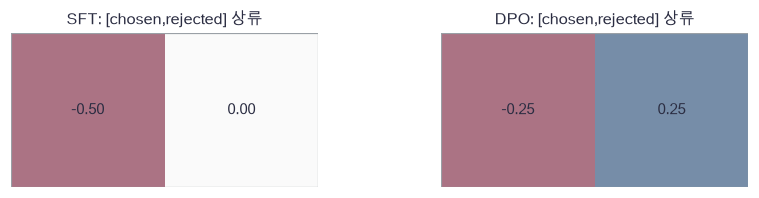

In [43]:
plot_objective_signals(sft_signal_hand,dpo_signal_hand)

🔍 **확인** · SFT는 chosen 확률을 올리려 합니다. DPO는 chosen/rejected의 상대 변화를 학습합니다. 실제 신경망의 공유 파라미터 때문에 한 번의 갱신이 모든 답변의 절대 확률에 주는 효과는 별도로 측정해야 합니다.

> **코드** · `rng.permutation(16)`은16개 조합 순서를 섞습니다. `rng.integers(N,size=8)`은 복원추출 배치입니다. `.copy()`는 방법별 파라미터 배열을 분리합니다. `tuple(value[indices] for value in batch)`는 입력·정답·mask의 같은 행을 고릅니다.

In [44]:
def make_preference_batches(pairs):
    """동일 prompt에 NEXT 정답과 COPY 오답을 붙여 선호 쌍을 만듭니다."""
    # 쓰는 것: response_batch (앞 절의 정의·실행 셀)
    prompts=[[5,fruit,color,3] for fruit,color in pairs]
    chosen=[[6+(color-6+1)%4] for fruit,color in pairs]
    rejected=[[color] for fruit,color in pairs]
    return response_batch(prompts,chosen),response_batch(prompts,rejected)

In [45]:
def train_preference(base,train_batches,valid_batches,method,steps=300,beta=.5):
    """같은 base·배치 순서에서 chosen SFT 또는 고정 reference DPO를 학습합니다."""
    # 쓰는 것: adam_state, adam_update, decoder_loss, dpo_loss, sequence_forward (앞 절의 정의·실행 셀)
    parameters={name:value.copy() for name,value in base.items()}
    state=adam_state(parameters)
    train_reference=tuple(sequence_forward(batch,base)[0] for batch in train_batches)
    valid_reference=tuple(sequence_forward(batch,base)[0] for batch in valid_batches)
    rng=np.random.default_rng(4902)
    history=[]
    for step in range(steps+1):
        if step%100==0:
            loss,_,margin,_,_=dpo_loss(*valid_batches,parameters,valid_reference,beta)
            history.append((step,loss,float(np.mean(margin>0))))
        if step==steps:
            break
        indices=rng.integers(len(train_batches[0][0]),size=8)
        chosen,rejected=[tuple(value[indices] for value in batch) for batch in train_batches]
        if method=='DPO':
            references=tuple(value[indices] for value in train_reference)
            _,gradients,_,_,_=dpo_loss(chosen,rejected,parameters,references,beta)
        elif method=='SFT':
            _,gradients,_,_=decoder_loss(*chosen[:3],parameters,weights=chosen[3])
        else:
            raise ValueError('method는 SFT 또는 DPO입니다')
        adam_update(parameters,gradients,state,learning_rate=.005)
    return parameters,np.array(history)

In [46]:
def evaluate_preference(parameters,batches,reference):
    """동일 답변 후보에 대한 원래 순위와 reference 대비 margin을 따로 셉니다."""
    # 쓰는 것: preference_loss, sequence_forward (앞 절의 정의·실행 셀)
    scores=[sequence_forward(batch,parameters)[0] for batch in batches]
    references=[sequence_forward(batch,reference)[0] for batch in batches]
    loss,_,margin=preference_loss(*scores,*references)
    return {'DPO loss':float(loss),'raw pair acc':float(np.mean(scores[0]>scores[1])),
            'relative pair acc':float(np.mean(margin>0)),
            'chosen mean logp':float(scores[0].mean()),'rejected mean logp':float(scores[1].mean())}

In [47]:
# 쓰는 것: response_batch, train_decoder (앞 절의 정의·실행 셀)
pairs=[(fruit,color) for fruit in range(10,14) for color in range(6,10)]
order=np.random.default_rng(4900).permutation(16)
parts=[[pairs[i] for i in indices] for indices in [order[:12],order[12:14],order[14:]]]
assert not set(parts[0])&set(parts[2]), 'train과 test의 prompt 조합은 겹치면 안 됩니다'
preference_batches=[make_preference_batches(part) for part in parts]
copy_train=response_batch([[4,fruit,color,3] for fruit,color in parts[0]],[[color] for fruit,color in parts[0]])
copy_valid=response_batch([[4,fruit,color,3] for fruit,color in parts[1]],[[color] for fruit,color in parts[1]])
reference,pretrain_history=train_decoder(copy_train[:3],copy_valid[:3],14,seed=49,steps=200)
reference_snapshot={name:value.copy() for name,value in reference.items()}

In [48]:
models={'reference':reference}
preference_histories={}
for method in ['SFT','DPO']:
    models[method],preference_histories[method]=train_preference(reference,*preference_batches[:2],method)
for name in reference:
    np.testing.assert_array_equal(reference[name],reference_snapshot[name])  # 검산: 두 학습 후 reference 배열 완전 불변
print('고정 reference 검산 통과; 학습은 방법마다 300회입니다')

고정 reference 검산 통과; 학습은 방법마다 300회입니다


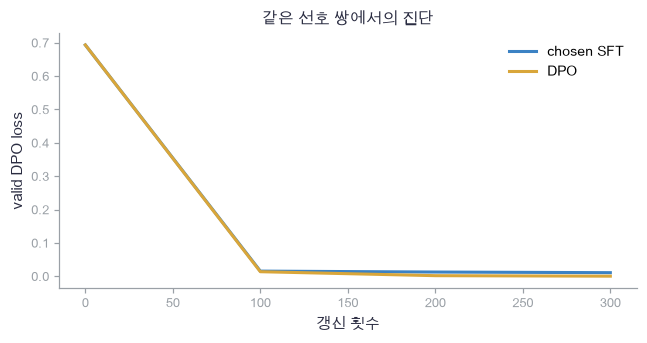

In [49]:
plot_dpo_learning([preference_histories[name] for name in ['SFT','DPO']],['chosen SFT','DPO'])

🔍 **확인** · 두 곡선은 같은 valid 후보 쌍에 대한 DPO 진단입니다. SFT가 실제 최적화한 목적은 답변 CE입니다. 이 그림만으로 생성 성공이나 다른 prompt 일반화를 결론내리지 않습니다.

### ✏️ 연습 4 · 두 경로의 미분 더하기

공유 파라미터의 chosen/rejected 기울기를 합치세요.

In [50]:
def exercise_paths(chosen_grad, rejected_grad):
    """두 경로의 미분 더하기의 계산을 완성합니다."""
    ### 구현할 내용: 공유 파라미터의 chosen/rejected 기울기를 합치세요.
    raise NotImplementedError
    return gradient

In [51]:
def check_paths(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([1.,2.]),np.array([-.5,3.])),[.5,5.])  # 검산: 두 경로 누적
    print("연습 4 통과")

run_check(check_paths, exercise_paths, hint="두 경로의 미분 더하기의 수식과 축을 확인하세요.")

☐ exercise_paths: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 두 경로의 미분 더하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = chosen_grad + rejected_grad
```

</details>

## 🔑 5. 선호 후보의 순위와 자유 생성을 따로 봅니다

**이 절에서 가져갈 것:** DPO margin이 좋아져도 chosen의 절대 확률이나 자유 생성이 좋아진다고 단정하지 않습니다.

후보 `초록`과 `빨강`의 순위를 맞혀도 모델이 실제로는 `COPY SEP COPY…`를 생성할 수 있습니다. 두 후보 이외의 어휘에도 확률이 남아 있기 때문입니다. test의 두 고유 prompt에서 raw 순위 $\ell^+>\ell^-$, relative 순위 $m>0$, chosen/rejected 절대 로그확률과 자유 생성을 모두 봅니다. 동률은 이 두 정확도에서 실패로 셉니다.

자유 생성은 정답 token을 넣지 않고 BOS+prompt에서 시작해 argmax로 한 token씩 붙입니다. PAD/BOS는 후보에서 제외하고 EOS 또는4개 생성 상한에서 멈춥니다. 성공은 **EOS까지 답변 전체 일치**입니다. 상한 종료도 평가에서 제외하지 않습니다.

또한 긴 답변은 더 많은 음의 log probability를 더합니다. DPO에서 길이가 사라지는 것은 아닙니다. 임의로 평균으로 바꾸지 말고 길이 분포와 EOS를 명시해야 합니다.

In [52]:
# 쓰는 것: evaluate_preference, models, preference_batches, reference (앞 절의 정의·실행 셀)
test_metrics={name:evaluate_preference(model,preference_batches[2],reference) for name,model in models.items()}
absolute_log_probs=np.array([[value['chosen mean logp'],value['rejected mean logp']] for value in test_metrics.values()])

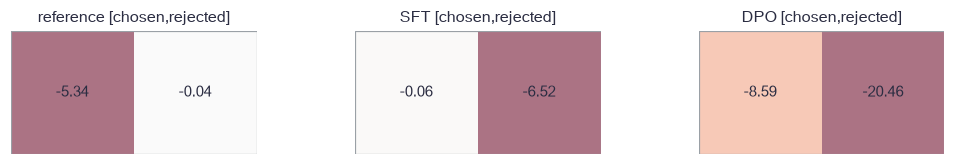

In [53]:
plot_absolute_probabilities(absolute_log_probs,list(models))

🔍 **확인** · DPO 목적은 두 열의 기준 대비 차이를 다룹니다. 두 절대 로그확률이 함께 내려가도 rejected가 더 내려가면 손실은 작아질 수 있습니다. 실제 출력 표와 자유 생성 결과로 이 가능성을 확인합니다. 이 두 후보의 차이는 정책 전체의 KL divergence가 아닙니다.

In [54]:
# 쓰는 것: greedy_decode, models, parts (앞 절의 정의·실행 셀)
for name,metrics in test_metrics.items():
    print(name,{key:round(value,4) for key,value in metrics.items()})
for name,model in models.items():
    successes=0
    for fruit,color in parts[2]:
        prefix=[1,5,fruit,color,3]
        generated,ended=greedy_decode(prefix,model,max_new_tokens=4)
        answer=generated[len(prefix):]
        expected=[6+(color-6+1)%4,2]
        successes+=int(answer==expected)
        print(name,'prompt',prefix,'생성',answer,'정답',expected,'EOS',ended)
    print(name,'전체 일치',successes,'/',len(parts[2]))

reference {'DPO loss': 0.6931, 'raw pair acc': 0.0, 'relative pair acc': 0.0, 'chosen mean logp': -5.3424, 'rejected mean logp': -0.04}
SFT {'DPO loss': 0.0028, 'raw pair acc': 1.0, 'relative pair acc': 1.0, 'chosen mean logp': -0.0565, 'rejected mean logp': -6.5218}
DPO {'DPO loss': 0.0002, 'raw pair acc': 1.0, 'relative pair acc': 1.0, 'chosen mean logp': -8.5897, 'rejected mean logp': -20.4559}
reference prompt [1, 5, 11, 8, 3] 생성 [8, 2] 정답 [9, 2] EOS True
reference prompt [1, 5, 10, 6, 3] 생성 [6, 2] 정답 [7, 2] EOS True
reference 전체 일치 0 / 2
SFT prompt [1, 5, 11, 8, 3] 생성 [9, 2] 정답 [9, 2] EOS True
SFT prompt [1, 5, 10, 6, 3] 생성 [7, 2] 정답 [7, 2] EOS True
SFT 전체 일치 2 / 2
DPO prompt [1, 5, 11, 8, 3] 생성 [4, 3, 4, 3] 정답 [9, 2] EOS False
DPO prompt [1, 5, 10, 6, 3] 생성 [8, 4, 9, 4] 정답 [7, 2] EOS False
DPO 전체 일치 0 / 2


In [55]:
def check_padding_log_probability():
    """PAD 폭·PAD ID 변경이 선택 답변 합과 미분에 영향을 주지 않는지 검산합니다."""
    # 쓰는 것: init_decoder, response_batch, sequence_backward, sequence_forward (앞 절의 정의·실행 셀)
    parameters=init_decoder(9,width=3,hidden=4,max_length=9,seed=4903)
    batch=response_batch([[4,3],[4,6,3]],[[7],[7,8]])
    score,cache=sequence_forward(batch,parameters)
    gradients,dx=sequence_backward(np.array([.3,-.7]),cache,parameters)
    changed=tuple(np.pad(value,((0,0),(0,2))) for value in batch)
    changed[0][~changed[2]]=8
    changed_score,changed_cache=sequence_forward(changed,parameters)
    changed_gradients,changed_dx=sequence_backward(np.array([.3,-.7]),changed_cache,parameters)
    np.testing.assert_allclose(score,changed_score,atol=1e-12)  # 검산: PAD 값·폭 불변
    for name in gradients:
        np.testing.assert_allclose(gradients[name],changed_gradients[name],atol=1e-12)  # 검산: PAD 추가 후 전체 미분 불변
    assert np.all(changed_dx[~changed[2]]==0), 'PAD embedding 입력 미분은0입니다'
    print('PAD 폭·값·전체 미분 검산 통과')

In [56]:
check_padding_log_probability()
short_sum=np.log(.6)+np.log(.8)
long_sum=np.log(.6)+np.log(.6)+np.log(.8)
assert long_sum<short_sum, '같은 조건부 수치 예에서 추가 token은 sequence logp를 낮춥니다'
print('길이2/3 합:',round(short_sum,3),round(long_sum,3),'평균:',round(short_sum/2,3),round(long_sum/3,3))

PAD 폭·값·전체 미분 검산 통과
길이2/3 합: -0.734 -1.245 평균: -0.367 -0.415


### ✏️ 연습 5 · EOS까지 전체 일치

생성 답변과 정답 답변이 모두 같은지 채우세요.

In [57]:
def exercise_exact(generated, expected):
    """EOS까지 전체 일치의 계산을 완성합니다."""
    ### 구현할 내용: 생성 답변과 정답 답변이 모두 같은지 채우세요.
    raise NotImplementedError
    return matched

In [58]:
def check_exact(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([7,2],[7,2]), 'EOS까지 같으면 성공입니다'
    assert not candidate([7],[7,2]), 'EOS가 없으면 실패입니다'
    assert not candidate([7,2,3],[7,2]), '추가 token도 불일치입니다'
    print("연습 5 통과")

run_check(check_exact, exercise_exact, hint="EOS까지 전체 일치의 수식과 축을 확인하세요.")

☐ exercise_exact: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: EOS까지 전체 일치의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
matched = generated == expected
```

</details>

## ✏️ 끝 연습 A–D

선호 확률·gradient 부호·길이·평가 범위를 다시 확인합니다. 각 문제는 본문 모델을 바꾸지 않는 작은 독립 계산입니다.

### ✏️ 연습 A · 안정 선호 손실

margin으로 softplus 손실을 채우세요.

In [59]:
def exercise_softplus(margin):
    """안정 선호 손실의 계산을 완성합니다."""
    ### 구현할 내용: margin으로 softplus 손실을 채우세요.
    raise NotImplementedError
    return loss

In [60]:
def check_softplus(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,-1000.])),[np.log(2),1000.])  # 검산: 동률과 극단 margin
    print("연습 A 통과")

run_check(check_softplus, exercise_softplus, hint="안정 선호 손실의 수식과 축을 확인하세요.")

☐ exercise_softplus: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 안정 선호 손실의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = np.logaddexp(0., -margin)
```

</details>

### ✏️ 연습 B · chosen 상류 미분

N개 선호 쌍의 chosen 로그확률 미분을 채우세요.

In [61]:
def exercise_coef(margin, beta):
    """chosen 상류 미분의 계산을 완성합니다."""
    ### 구현할 내용: N개 선호 쌍의 chosen 로그확률 미분을 채우세요.
    raise NotImplementedError
    return coefficient

In [62]:
def check_coef(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,0.]),.5),[-.125,-.125])  # 검산: beta와 쌍 수 분모
    print("연습 B 통과")

run_check(check_coef, exercise_coef, hint="chosen 상류 미분의 수식과 축을 확인하세요.")

☐ exercise_coef: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: chosen 상류 미분의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
coefficient = beta * (sigmoid_stable(margin) - 1) / len(margin)
```

</details>

### ✏️ 연습 C · 절대 확률 변화

선택 답변의 전후 로그확률 변화량을 채우세요.

In [63]:
def exercise_change(after, before):
    """절대 확률 변화의 계산을 완성합니다."""
    ### 구현할 내용: 선택 답변의 전후 로그확률 변화량을 채우세요.
    raise NotImplementedError
    return change

In [64]:
def check_change(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([-5.,-9.]),np.array([-3.,-4.])),[-2.,-5.])  # 검산: 둘 다 줄어도 상대 차이는 개선될 수 있음
    print("연습 C 통과")

run_check(check_change, exercise_change, hint="절대 확률 변화의 수식과 축을 확인하세요.")

☐ exercise_change: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 절대 확률 변화의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
change = after - before
```

</details>

### ✏️ 연습 D · 선호 쌍 비율

동률을 실패로 하는 raw 선호 정확도를 채우세요.

In [65]:
def exercise_pairacc(chosen, rejected):
    """선호 쌍 비율의 계산을 완성합니다."""
    ### 구현할 내용: 동률을 실패로 하는 raw 선호 정확도를 채우세요.
    raise NotImplementedError
    return accuracy

In [66]:
def check_pairacc(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([-1.,-2.,-3.]),np.array([-2.,-2.,-1.])),1/3)  # 검산: 성공1·동률1·실패1
    print("연습 D 통과")

run_check(check_pairacc, exercise_pairacc, hint="선호 쌍 비율의 수식과 축을 확인하세요.")

☐ exercise_pairacc: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 선호 쌍 비율의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
accuracy = np.mean(chosen > rejected)
```

</details>

## ✏️ 준비도 확인

- **설명:** 선호 쌍 순위가 맞아도 자유 생성이 틀릴 수 있는 이유를 말할 수 있나요?
- **수식:** $\ell$의 token 합과 DPO의 선호 쌍 평균을 서로 다른 축으로 쓸 수 있나요?
- **구현:** 고정 reference를 미분하지 않고 chosen/rejected 두 경로를 공유 파라미터에 누적할 수 있나요?
- **변형 검산:** 답변 길이·PAD 폭·빈 답변·동률·EOS 미종료를 바꿔 무엇이 같아야 하는지 확인할 수 있나요?

## 📎 참고와 다음 연결

[DPO 원문](https://arxiv.org/abs/2305.18290)은 기준 정책 대비 log-ratio 목적의 근거입니다. 여기서는 한 층 decoder와 합성 선호로 계산 경로를 축소했습니다. [48 SFT·LoRA](48_sft_lora.ipynb)는 어떤 token과 파라미터를 학습할지 다룹니다. 50번은 이미지·텍스트의 조건을 결합하고, 62번은 학습한 선호 보상을 실제 정책 rollout·KL·PPO 갱신과 연결합니다. 현재 단원에는 reward model 학습이나 PPO가 없습니다.